In [166]:
from langgraph.graph import StateGraph, START, END
from pydantic import BaseModel, Field
from typing import TypedDict, Annotated, Literal

from langchain_openai import ChatOpenAI
from langchain_core.prompts import ChatPromptTemplate, PromptTemplate
from langchain_core.output_parsers import PydanticOutputParser, StrOutputParser
from langgraph.checkpoint.memory import InMemorySaver
import operator
from langgraph.graph.message import BaseMessage, add_messages

from dotenv import load_dotenv
load_dotenv()

True

In [167]:
# todos
    # - sequential workflow
    # - parallel workflow
    # - conditional workflow
    # - loop
    # - state

chatModel = ChatOpenAI()
strOutputParser = StrOutputParser()

class Review(BaseModel):
    review: str = Field(..., description="review")
    rating: int = Field(..., le=5, ge=1, description="rating")


In [168]:
class WikiContent(TypedDict):
    content: Annotated[str, 'content']
    topic: Annotated[str, 'topic']
    review: Annotated[list[str],  add_messages]
    rating: Annotated[int, 'rating between 1 - 5']
    

In [176]:
def generateContent(wikiContent: WikiContent) -> WikiContent:
    print("generateContent wiki content ", wikiContent)
    firstPrompt = PromptTemplate(template="Write a short description about this {topic}, keep the ans short in 20 words", input_variables=['topic'], validate_template=True)
    secondPrompt = PromptTemplate(template="Write a short description about this {topic}, Here is the old review {review}, keep the ans short in 20 words", input_variables=['topic', 'review'], validate_template=True)
    # print('intial rating ', wikiContent['rating'], type(wikiContent['rating']))
    if(False):
        chain = secondPrompt | chatModel | strOutputParser
        newContent = chain.invoke({"topic": wikiContent['topic']})
    else:
        # chain = firstPrompt | chatModel | strOutputParser
        # newContent = chain.invoke({'topic': wikiContent['topic']})
        newContent = 'asdf;lkj'
    wikiContent['content']  = newContent
    print("WikiContent post generation ", wikiContent['content'])
    return wikiContent

In [177]:
def getReview(wikiContent: WikiContent) -> WikiContent:
    firstPrompt = PromptTemplate(template="Get review about this topic ( {topic} ) content. This is the content i wrote {content},", input_variables=['topic', 'content'], validate_template=True)
    chain = firstPrompt | chatModel.with_structured_output(Review)
    review = chain.invoke({"topic": wikiContent['topic'], "content": wikiContent["content"]})
    print(review)
    # wikiContent['review'] = review['review']
    # wikiContent['rating'] = review['rating']
    return wikiContent

In [178]:
def router(wikiContent: WikiContent) -> Literal['done', 'not-done']:
    print("router ", wikiContent['review'][-1].content)
    isItDone = str(wikiContent['review'][-1].content).__contains__("SATISFIED")
    if (isItDone):
        return 'done'
    else:
        return "not-done"

In [179]:
graph = StateGraph(WikiContent)

In [180]:
graph.add_node('generate_content', generateContent)
graph.add_node('get_review', getReview)

graph.add_edge(START, 'generate_content')
graph.add_edge('generate_content', 'get_review')
graph.add_conditional_edges('get_review', router, {'done': END, 'not-done': 'generate_content'})


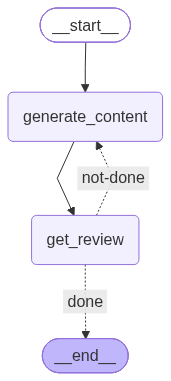

In [181]:
workflow = graph.compile()
workflow

In [182]:
workflow.invoke({"topic": "apple"})

generateContent wiki content  {'topic': 'apple', 'review': []}
WikiContent post generation  asdf;lkj


/Users/sriharshamadireddy/Desktop/Personal/Learning/DataScience/genai/venv/lib/python3.13/site-packages/langchain_openai/chat_models/base.py:2393: UserWarning: Cannot use method='json_schema' with model gpt-3.5-turbo since it doesn't support OpenAI's Structured Output API. You can see supported models here: https://platform.openai.com/docs/guides/structured-outputs#supported-models. To fix this warning, set `method='function_calling'. Overriding to method='function_calling'.
  warnings.warn(


review='asdf;lkj,' rating=4


IndexError: list index out of range

In [51]:
from langgraph.graph import StateGraph, START, END
from langchain_openai import ChatOpenAI
from dotenv import load_dotenv
from langchain_core.output_parsers import StrOutputParser, PydanticOutputParser
from langgraph.graph.message import BaseMessage, add_messages
from pydantic import  BaseModel, Field
from typing import TypedDict, Literal, Annotated
from langchain_core.prompts import PromptTemplate, ChatPromptTemplate



load_dotenv()

True

In [91]:
chatModel = ChatOpenAI(model='gpt-4o')
strOutputParser = StrOutputParser()

In [92]:
class Review(BaseModel):
    review: str = Field(..., description='Review')
    rating: int = Field(..., ge = 1, le = 5)

class State(TypedDict):
    topic: Annotated[str, "Topic"]
    content: Annotated[str, 'Content']
    review: Annotated[list[str], add_messages, 'Review']
    rating: Annotated[int, 'Rating']
    isFirstTime: Annotated[bool, False]
    count: Annotated[int,'count']



In [93]:
def generate_content(state: State)-> State: 
    firstTemplate = PromptTemplate(template="""
    Generate the content for this topic {topic}, keep the content short and crisp and under 30 words
    """, validate_template=True, input_variables=['topic'])

    secondPrompt = PromptTemplate(template="Write a short description about this {topic}, Here is the old review {review}, keep the ans short in 20 words", input_variables=['topic', 'review'], validate_template=True)

    isFirstTime = state['isFirstTime'] == True
    if(isFirstTime):
        chain = firstTemplate | chatModel | strOutputParser
        response = chain.invoke(state['topic'])
        state['content'] = "abcdefg"
        state['count'] = state['count'] + 1
    else:
        chain = secondPrompt | chatModel | strOutputParser
        review = state['review'][-1]
        rating = state['rating']
        topic = state['topic']
        state['count'] = state['count'] + 1
        state['content'] = chain.invoke({'topic': topic, 'review': review, 'rating': rating})
    return state



In [99]:
def get_review(state: State)-> State:
    print("review. ", state)
    firstPrompt = PromptTemplate(template="This is the content {content}, i wrote for this topic {topic}, please review it and get the review and rating of contnet matching with the topic", input_variables=['topic', 'content'], validate_template=True)
    chain = firstPrompt | chatModel.with_structured_output(Review)
    response = chain.invoke({"topic": state['topic'], "content": state["content"]})
    print("get_reivew[respne] ", response.model_dump_json())
    state['review'] = response.review
    state['rating'] = response.rating
    state['isFirstTime'] = False
    return state
    

In [100]:
def router(state: State)->Literal['done','notDone']:
    rating = state['rating']
    if(rating > 2):
         return 'done'
    else:
         return 'notDone'


In [101]:
state = StateGraph(State)

state.add_node('create_content', generate_content)
state.add_node('get_review', get_review)

state.add_edge(START, 'create_content')
state.add_edge('create_content', 'get_review')
state.add_conditional_edges('get_review', router, {'done': END, 'notDone': 'create_content'})
state.add_edge('get_review', END)


workflow = state.compile()


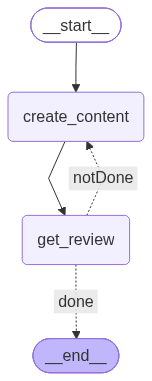

In [102]:
workflow

In [103]:
workflow.invoke({'topic': 'apple', 'count':0, 'isFirstTime': True})

review.  {'topic': 'apple', 'content': 'abcdefg', 'isFirstTime': True, 'count': 1}
get_reivew[respne]  {"review":"Upon reading your content of \"abcdefg\" for the topic \"apple,\" it seems you've provided a placeholder or string that does not directly relate or convey any meaningful information about the subject of \"apple.\" Here is a breakdown:\n\n1. **Relevance to Topic:** \n   - The provided content \"abcdefg\" does not contain information or context that pertains to \"apple,\" whether as a fruit, brand, or metaphor. \n   - It's important for content to be tailored to its topic by including relevant facts, insights, and discussion.\n\n2. **Content Suggestions:**\n   - Explore different aspects or perspectives about apples. For instance, you can talk about the nutritional benefits of apples, the variations among different types of apples, or even delve into discussing Apple as a tech company.\n   - Use descriptive language and informative sentences to elaborate on thoughts.\n\n3. **

{'topic': 'apple',
 'content': 'This apple is crisp, juicy, and sweet with a hint of tartness, offering a perfect balance of flavor.',
 'review': 'Your description serves as a delightful and sensory appeal to anyone eager to know about this apple. By using vivid adjectives like "crisp," "juicy," "sweet," and "hint of tartness," you successfully paint a picture of what one might experience when biting into this fruit. Here\'s a brief review and an assessment of your content:\n\n### Review\n\n**Pros:**\n1. **Descriptive Language:** The use of adjectives captures the essence of the apple quite effectively.\n2. **Flavor Balance:** Describing the "perfect balance of flavor" makes it appealing and can entice readers.\n3. **Engaging:** The concise and inviting nature of your sentence draws attention.\n\n**Areas for Improvement:**\n1. **Variety Identification:** Specifying the variety of the apple might add more context, helping the reader know precisely which type they might be engaging with.